# Numerical exercises 6
## Exercise 06.1

Complete the NSL_simulator code to simulate a 1D Ising model with the Gibbs sampling algorithm (the Metropolis algorithm is already implemented) to sample the Boltzmann's weight $p(\{ s_i \}) = \exp(-\beta H)/Z$. Verify the possibility to restart from a previous spin configuration.

The code already computes the internal energy: $U(N,T) = \langle H \rangle$. Add the calculation of $C(N,T)$, $\chi(N,T)$, $M(N,T,h)$ and compute:
1. $U(N,T) = \langle H \rangle_{h=0}$
2. $C(N,T) = k_B \beta^2 (\langle H^2 \rangle_{h=0}-\langle H \rangle_{h=0}^2)$ 
3. $\chi(N,T) = \beta \langle (\sum_{i=1,N}s_i)^2 \rangle_{h=0}$
4. $M(N,T,h=0.02)= \langle \sum_{i=1,N}s_i \rangle_{h=0.02}$

as a function of $T$ in the range $\left[0.5;2.0\right]$ for a system of $N=50$ spins with $J=1$.

As usual, use data blocking and give an estimate of the statistical uncertainties.
### **Solution**
### The Metropolis Algorithm
As already seen in the previous exercise, the Metropolis algorithm is a fundamental Markov Chain Monte Carlo (MCMC) method used to sample from a target thermodynamic distribution. 
* **Proposal:** A random local update is proposed (e.g., flipping a spin).
* **Acceptance Rule:** The move is evaluated based on the energy change ($\Delta E$). It is accepted unconditionally if the energy decreases ($\Delta E \le 0$), and accepted with probability $p = e^{-\beta \Delta E}$ if the energy increases.
### Gibbs Sampling (Heat-Bath)
Gibbs sampling is an MCMC technique where proposed transitions are always accepted.
* **Proposal:** A variable is updated by sampling a new value directly from its local conditional probability distribution, keeping all neighboring variables fixed. 
* **The Formula:** For a 1D Ising system, the probability of setting a spin $s_i$ to $+1$ depends entirely on the effective field $h_{eff} = J(s_{left} + s_{right}) + h$ generated by its neighbors:
$$ p(s_i = +1) = \frac{1}{1 + e^{-2\beta h_{eff}}} $$
* **Acceptance Rule:** Since the new value is drawn exactly from this local Boltzmann weight, the acceptance probability is inherently 100%.



### Instantaneous Thermodynamic Measurements
The code evaluates the lattice properties at each Monte Carlo step and accumulates them into blocks:

- **Magnetization ($M/N$):** Sums the value of all spins and divides by the number of particles `_npart`. It calculates the actual average magnetization per spin of the current configuration.
- **Specific Heat ($C_v$):** The code saves the square of the instantaneous energy ($E^2$). This is because specific heat is related to energy variance ($C \propto \langle E^2 \rangle - \langle E \rangle^2$). By accumulating $E^2$ here, the variance can be correctly computed at the end of the block.
- **Susceptibility ($\chi$):** Similar to specific heat, the code saves the square of the magnetization ($M^2$). Since average magnetization $\langle M \rangle$ tends to zero at zero external field, susceptibility is derived directly from the fluctuations of $M^2$ ($\chi = \beta \langle M^2 \rangle$).

### Equilibration Phase
To ensure the system reaches thermodynamic equilibrium before data collection, a dedicated equilibration function was implemented. This function performs single-block Monte Carlo steps without accumulating any measurements, allowing the system to properly thermalize from its initial configuration.

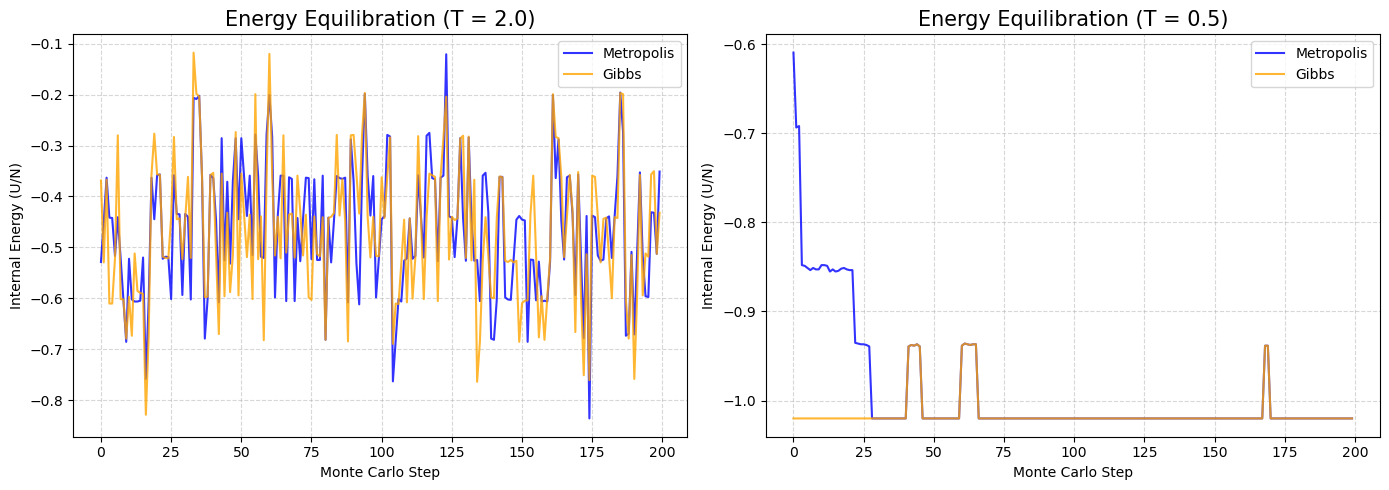

In [31]:
import numpy as np
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# ==========================================
# LEFT PLOT: T = 2.0
# ==========================================
metro_2 = np.loadtxt("METRO/OUTPUT/equil_2.dat")
gibbs_2 = np.loadtxt("GIBBS/OUTPUT/equil_2.dat")

x_m2 = metro_2[:, 0] if metro_2.ndim > 1 else np.arange(len(metro_2))
y_m2 = metro_2[:, 1] if metro_2.ndim > 1 else metro_2
x_g2 = gibbs_2[:, 0] if gibbs_2.ndim > 1 else np.arange(len(gibbs_2))
y_g2 = gibbs_2[:, 1] if gibbs_2.ndim > 1 else gibbs_2

ax1.plot(x_m2, y_m2, label="Metropolis", alpha=0.8, color="blue")
ax1.plot(x_g2, y_g2, label="Gibbs", alpha=0.8, color="orange")
ax1.set_title("Energy Equilibration (T = 2.0)", fontsize="15")
ax1.set_xlabel("Monte Carlo Step")
ax1.set_ylabel("Internal Energy (U/N)")
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

# ==========================================
# RIGHT PLOT: T = 0.5
# ==========================================
metro_05 = np.loadtxt("METRO/OUTPUT/equil_05.dat")
gibbs_05 = np.loadtxt("GIBBS/OUTPUT/equil_05.dat")

x_m05 = metro_05[:, 0] if metro_05.ndim > 1 else np.arange(len(metro_05))
y_m05 = metro_05[:, 1] if metro_05.ndim > 1 else metro_05
x_g05 = gibbs_05[:, 0] if gibbs_05.ndim > 1 else np.arange(len(gibbs_05))
y_g05 = gibbs_05[:, 1] if gibbs_05.ndim > 1 else gibbs_05

ax2.plot(x_m05, y_m05, label="Metropolis", alpha=0.8, color="blue")
ax2.plot(x_g05, y_g05, label="Gibbs", alpha=0.8, color="orange")
ax2.set_title("Energy Equilibration (T = 0.5)", fontsize="15")
ax2.set_xlabel("Monte Carlo Step")
ax2.set_ylabel("Internal Energy (U/N)")
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()

* **High Temperature (T = 2.0):** The left plot shows large and rapid fluctuations of the internal energy between approximately -0.8 and -0.1 for both algorithms. The small numer of spin allows the system to freely explore the phase space, reaching thermodynamic equilibrium almost instantaneously without obvious transition phases.
* **Low Temperature (T = 0.5):** The right plot highlights a much more rigid behavior. The Metropolis algorithm (blue line) starts from a higher energy and takes about 30 Monte Carlo steps to relax in steps towards the minimum energy state (around -1.0). The Gibbs algorithm (orange line), on the other hand, starts the measurement already from a thermalized low-energy configuration.

Hence, I chose to mantain an equilibration of 200 step at every temperature.

### Simulation
The `run.sh` script automates the multi-phase execution of the 1D Ising model simulation by dynamically managing input parameters and orchestrating a gradual cooling process.

* **Temperature Iteration:** It loops from $T=2.0$ down to $T=0.5$ in steps of 0.1.
* **Two-Phase Execution:**
  * **Phase 1 ($h=0.0$):** Simulates the system without an external field to measure Internal Energy ($U$), Heat Capacity ($C_v$), and Magnetic Susceptibility ($\chi$).
  * **Phase 2 ($h=0.02$):** Reruns the temperature loop with a weak external field to correctly sample the Magnetization ($M$).
* **Dynamic Input Modification:** It automatically updates the `input.dat` file for each temperature step before launching the C++ executable.
* **Thermal Chain (Restart):** After the first simulation at $T=2.0$, it toggles the restart flag (`RESTART=1`). This allows each subsequent lower-temperature step to inherit the thermalized spin configuration of the previous one, vastly improving the equilibration efficiency as the system cools down.

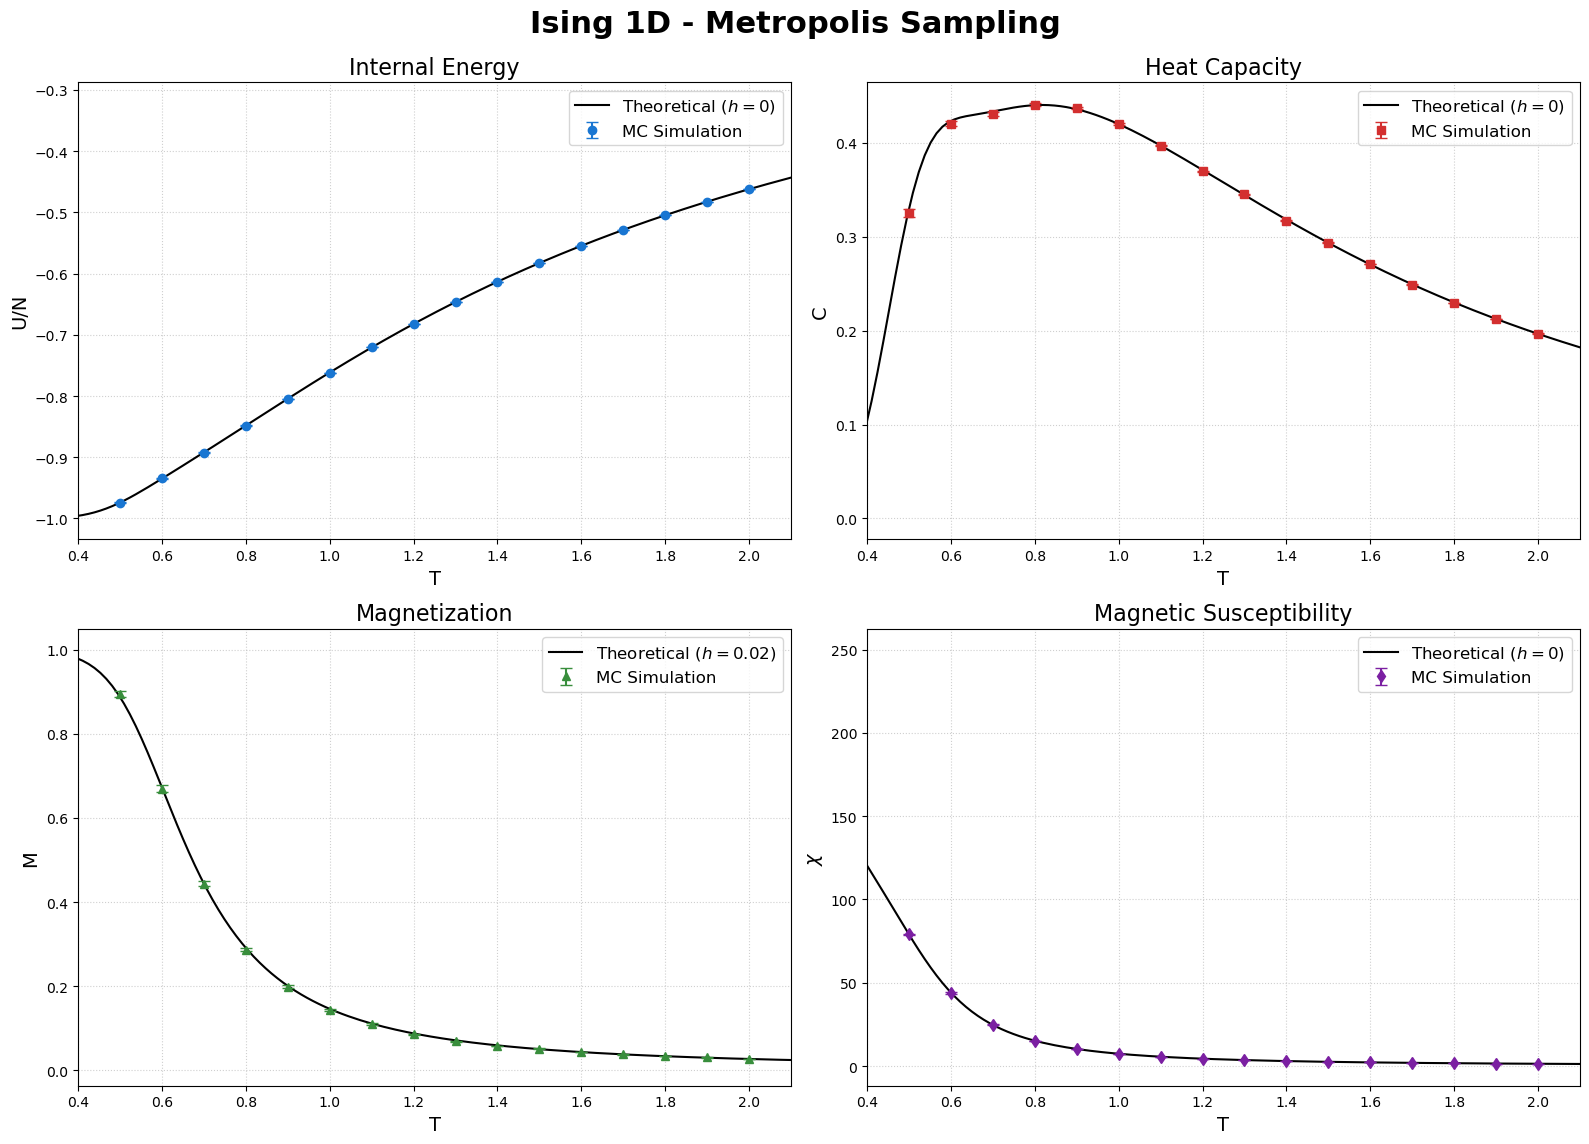

In [ ]:
points = 200
T_th = np.linspace(0.2, 3.0, num=points)
beta_th = 1.0 / T_th
J = 1.0
Ns = 50
h = 0.02

# 1. Energia interna (h = 0)
th = np.tanh(J / T_th)
thN = th**Ns
ch = 1.0 / th
e_th = -J * (th + ch * thN) / (1.0 + thN)

# 2. Calore specifico (h = 0)
cv_th = ((beta_th * J)**2) * (
    ((1.0 + thN + (Ns - 1) * (th**2) + (Ns - 1) * (ch**2) * thN) / (1.0 + thN))
    - Ns * ((th + ch * thN) / (1.0 + thN))**2
)

# 3. Magnetizzazione (h = 0.02)
sqrt_term = np.sqrt(np.exp(2 * beta_th * J) * (np.cosh(beta_th * h)**2) - 2 * np.sinh(2 * beta_th * J))
l1 = np.exp(beta_th * J) * np.cosh(beta_th * h) + sqrt_term
l2 = np.exp(beta_th * J) * np.cosh(beta_th * h) - sqrt_term
Z = l1**Ns + l2**Ns
M_th = (np.exp(beta_th * J) * np.sinh(beta_th * h) * (
    (l1**(Ns - 1)) * (1.0 + np.exp(beta_th * J) * np.cosh(beta_th * h) / sqrt_term)
    + (l2**(Ns - 1)) * (1.0 - np.exp(beta_th * J) * np.cosh(beta_th * h) / sqrt_term)
)) / Z

# 4. Suscettività (h = 0)
chi_th = beta_th * np.exp(2 * beta_th * J) * (1.0 - thN) / (1.0 + thN)

OUTPUT_DIR = "METRO/OUTPUT" 

fig, axs = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Ising 1D - Metropolis Sampling', fontsize=22, fontweight='bold', y=0.95)

# --- 1. TOTAL ENERGY (U/N) ---
t_sim, u_sim, err_u = np.loadtxt(f"{OUTPUT_DIR}/summary_energy.dat", unpack=True)
axs[0, 0].plot(T_th, e_th, color='black', label='Theoretical ($h=0$)', linewidth=1.5)
axs[0, 0].errorbar(t_sim, u_sim, yerr=err_u, fmt='o', color='#1976D2', ecolor='#1976D2', 
                   capsize=4, markersize=6, label='MC Simulation')
axs[0, 0].set_title('Internal Energy', fontsize=16)
axs[0, 0].set_xlabel('T', fontsize=14)
axs[0, 0].set_ylabel('U/N', fontsize=14)
axs[0, 0].set_xlim(0.4, 2.1)
axs[0, 0].grid(True, linestyle=':', alpha=0.6)
axs[0, 0].legend(fontsize=12)

# --- 2. SPECIFIC HEAT (C) ---
t_sim, cv_sim, err_cv = np.loadtxt(f"{OUTPUT_DIR}/summary_cv.dat", unpack=True)
axs[0, 1].plot(T_th, cv_th, color='black', label='Theoretical ($h=0$)', linewidth=1.5)
axs[0, 1].errorbar(t_sim, cv_sim, yerr=err_cv, fmt='s', color='#D32F2F', ecolor='#D32F2F', 
                   capsize=4, markersize=6, label='MC Simulation')
axs[0, 1].set_title('Heat Capacity', fontsize=16)
axs[0, 1].set_xlabel('T', fontsize=14)
axs[0, 1].set_ylabel('C', fontsize=14)
axs[0, 1].set_xlim(0.4, 2.1)
axs[0, 1].grid(True, linestyle=':', alpha=0.6)
axs[0, 1].legend(fontsize=12)

# --- 3. MAGNETIZATION (M) ---
t_sim, m_sim, err_m = np.loadtxt(f"{OUTPUT_DIR}/summary_mag.dat", unpack=True)
axs[1, 0].plot(T_th, M_th, color='black', label='Theoretical ($h=0.02$)', linewidth=1.5)
axs[1, 0].errorbar(t_sim, m_sim, yerr=err_m, fmt='^', color='#388E3C', ecolor='#388E3C', 
                   capsize=4, markersize=6, label='MC Simulation')
axs[1, 0].set_title('Magnetization', fontsize=16)
axs[1, 0].set_xlabel('T', fontsize=14)
axs[1, 0].set_ylabel('M', fontsize=14)
axs[1, 0].set_xlim(0.4, 2.1)
axs[1, 0].grid(True, linestyle=':', alpha=0.6)
axs[1, 0].legend(fontsize=12)

# --- 4. SUSCEPTIBILITY (chi) ---
t_sim, chi_sim, err_chi = np.loadtxt(f"{OUTPUT_DIR}/summary_chi.dat", unpack=True)
axs[1, 1].plot(T_th, chi_th, color='black', label='Theoretical ($h=0$)', linewidth=1.5)
axs[1, 1].errorbar(t_sim, chi_sim, yerr=err_chi, fmt='d', color='#7B1FA2', ecolor='#7B1FA2', 
                   capsize=4, markersize=6, label='MC Simulation')
axs[1, 1].set_title('Magnetic Susceptibility', fontsize=16)
axs[1, 1].set_xlabel('T', fontsize=14)
axs[1, 1].set_ylabel(r'$\chi$', fontsize=14)
axs[1, 1].set_xlim(0.4, 2.1)
axs[1, 1].grid(True, linestyle=':', alpha=0.6)
axs[1, 1].legend(fontsize=12)

# Regolazione degli spazi per non sovrapporre i titoli
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

**Plot parameters**
* $M = 10^6$ 
* $N = 10^2$
* $L = 10^4$

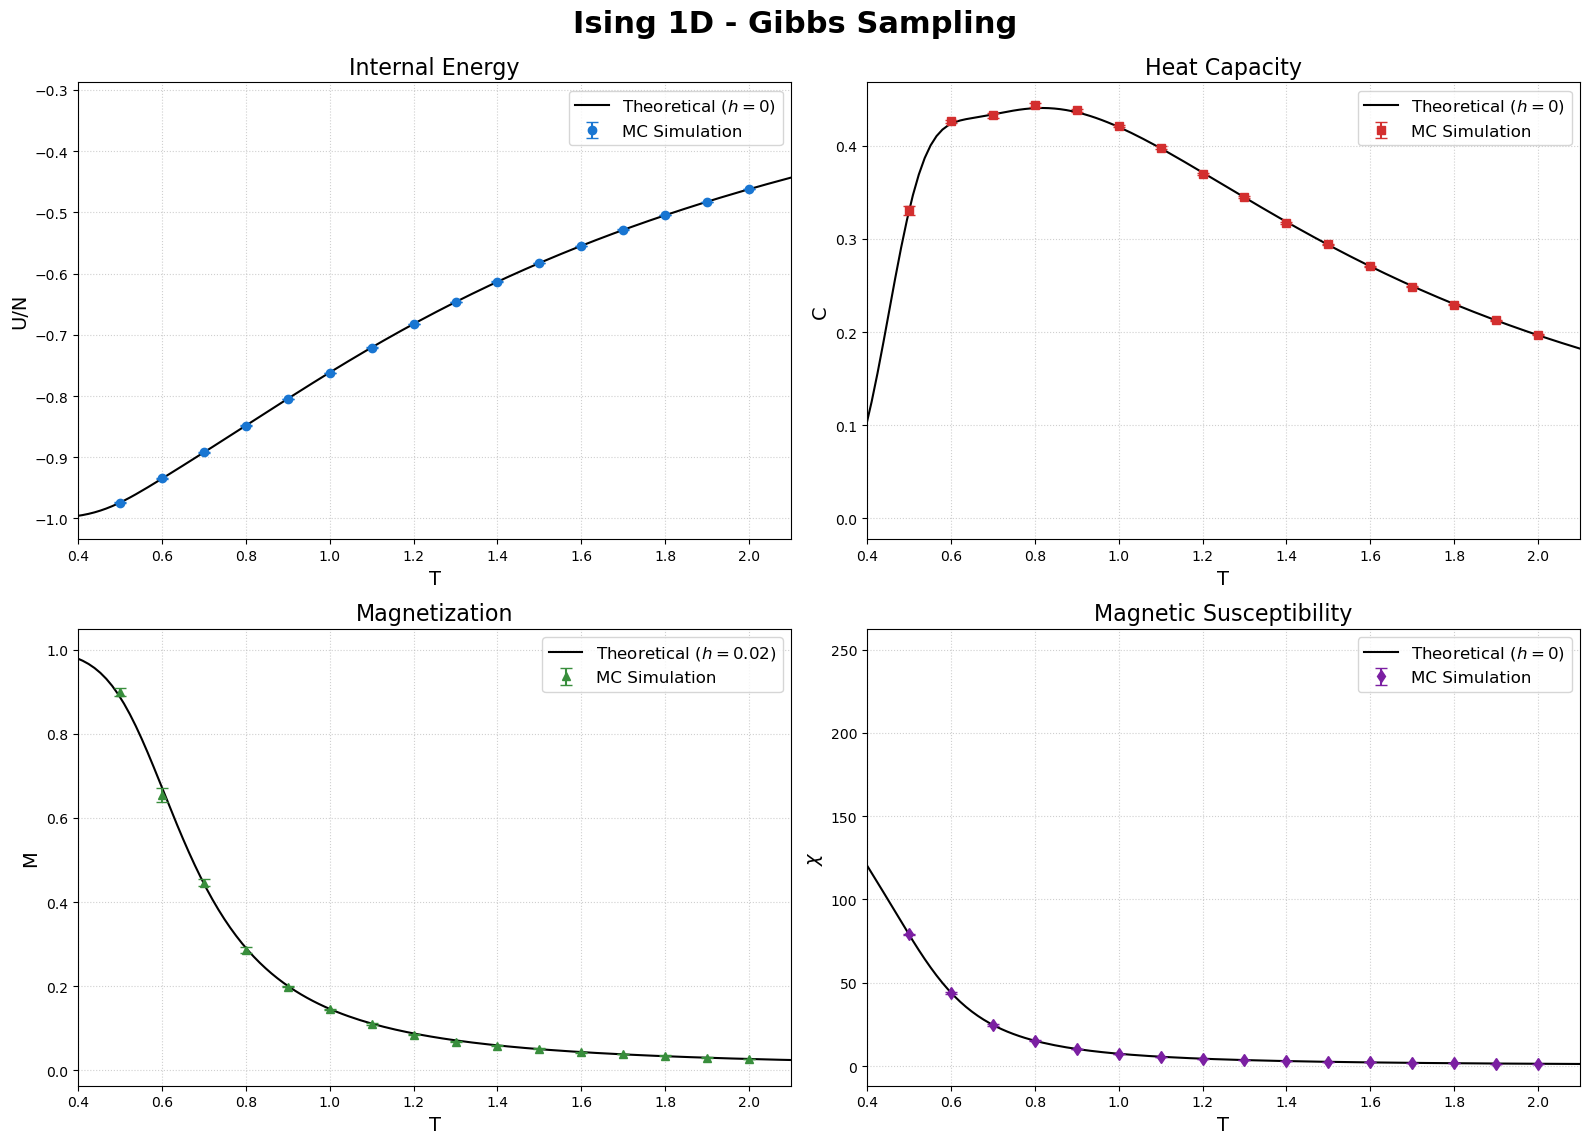

In [17]:
# ==========================================
# CURVE TEORICHE
# ==========================================
points = 200
T_th = np.linspace(0.2, 3.0, num=points)
beta_th = 1.0 / T_th
J = 1.0
Ns = 50
h = 0.02

# 1. Energia interna (h = 0)
th = np.tanh(J / T_th)
thN = th**Ns
ch = 1.0 / th
e_th = -J * (th + ch * thN) / (1.0 + thN)

# 2. Calore specifico (h = 0)
cv_th = ((beta_th * J)**2) * (
    ((1.0 + thN + (Ns - 1) * (th**2) + (Ns - 1) * (ch**2) * thN) / (1.0 + thN))
    - Ns * ((th + ch * thN) / (1.0 + thN))**2
)

# 3. Magnetizzazione (h = 0.02)
sqrt_term = np.sqrt(np.exp(2 * beta_th * J) * (np.cosh(beta_th * h)**2) - 2 * np.sinh(2 * beta_th * J))
l1 = np.exp(beta_th * J) * np.cosh(beta_th * h) + sqrt_term
l2 = np.exp(beta_th * J) * np.cosh(beta_th * h) - sqrt_term
Z = l1**Ns + l2**Ns
M_th = (np.exp(beta_th * J) * np.sinh(beta_th * h) * (
    (l1**(Ns - 1)) * (1.0 + np.exp(beta_th * J) * np.cosh(beta_th * h) / sqrt_term)
    + (l2**(Ns - 1)) * (1.0 - np.exp(beta_th * J) * np.cosh(beta_th * h) / sqrt_term)
)) / Z

# 4. Suscettività (h = 0)
chi_th = beta_th * np.exp(2 * beta_th * J) * (1.0 - thN) / (1.0 + thN)


# ==========================================
# IMPOSTAZIONE GRAFICA 2x2
# ==========================================
OUTPUT_DIR = "GIBBS/OUTPUT" # Modifica se necessario (es. "METRO/OUTPUT")

fig, axs = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Ising 1D - Gibbs Sampling', fontsize=22, fontweight='bold', y=0.95)

# --- 1. TOTAL ENERGY (U/N) ---
t_sim, u_sim, err_u = np.loadtxt(f"{OUTPUT_DIR}/summary_energy.dat", unpack=True)
axs[0, 0].plot(T_th, e_th, color='black', label='Theoretical ($h=0$)', linewidth=1.5)
axs[0, 0].errorbar(t_sim, u_sim, yerr=err_u, fmt='o', color='#1976D2', ecolor='#1976D2', 
                   capsize=4, markersize=6, label='MC Simulation')
axs[0, 0].set_title('Internal Energy', fontsize=16)
axs[0, 0].set_xlabel('T', fontsize=14)
axs[0, 0].set_ylabel('U/N', fontsize=14)
axs[0, 0].set_xlim(0.4, 2.1)
axs[0, 0].grid(True, linestyle=':', alpha=0.6)
axs[0, 0].legend(fontsize=12)

# --- 2. SPECIFIC HEAT (C) ---
t_sim, cv_sim, err_cv = np.loadtxt(f"{OUTPUT_DIR}/summary_cv.dat", unpack=True)
axs[0, 1].plot(T_th, cv_th, color='black', label='Theoretical ($h=0$)', linewidth=1.5)
axs[0, 1].errorbar(t_sim, cv_sim, yerr=err_cv, fmt='s', color='#D32F2F', ecolor='#D32F2F', 
                   capsize=4, markersize=6, label='MC Simulation')
axs[0, 1].set_title('Heat Capacity', fontsize=16)
axs[0, 1].set_xlabel('T', fontsize=14)
axs[0, 1].set_ylabel('C', fontsize=14)
axs[0, 1].set_xlim(0.4, 2.1)
axs[0, 1].grid(True, linestyle=':', alpha=0.6)
axs[0, 1].legend(fontsize=12)

# --- 3. MAGNETIZATION (M) ---
t_sim, m_sim, err_m = np.loadtxt(f"{OUTPUT_DIR}/summary_mag.dat", unpack=True)
axs[1, 0].plot(T_th, M_th, color='black', label='Theoretical ($h=0.02$)', linewidth=1.5)
axs[1, 0].errorbar(t_sim, m_sim, yerr=err_m, fmt='^', color='#388E3C', ecolor='#388E3C', 
                   capsize=4, markersize=6, label='MC Simulation')
axs[1, 0].set_title('Magnetization', fontsize=16)
axs[1, 0].set_xlabel('T', fontsize=14)
axs[1, 0].set_ylabel('M', fontsize=14)
axs[1, 0].set_xlim(0.4, 2.1)
axs[1, 0].grid(True, linestyle=':', alpha=0.6)
axs[1, 0].legend(fontsize=12)

# --- 4. SUSCEPTIBILITY (chi) ---
t_sim, chi_sim, err_chi = np.loadtxt(f"{OUTPUT_DIR}/summary_chi.dat", unpack=True)
axs[1, 1].plot(T_th, chi_th, color='black', label='Theoretical ($h=0$)', linewidth=1.5)
axs[1, 1].errorbar(t_sim, chi_sim, yerr=err_chi, fmt='d', color='#7B1FA2', ecolor='#7B1FA2', 
                   capsize=4, markersize=6, label='MC Simulation')
axs[1, 1].set_title('Magnetic Susceptibility', fontsize=16)
axs[1, 1].set_xlabel('T', fontsize=14)
axs[1, 1].set_ylabel(r'$\chi$', fontsize=14)
axs[1, 1].set_xlim(0.4, 2.1)
axs[1, 1].grid(True, linestyle=':', alpha=0.6)
axs[1, 1].legend(fontsize=12)

# Regolazione degli spazi per non sovrapporre i titoli
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

**Plot parameters**
* $M = 5 \times 10^6$ 
* $N = 10^2$
* $L = 5 \times 10^4$
### Block Size Requirement: Gibbs vs. Metropolis

Gibbs sampling exhibits longer autocorrelation times than Metropolis at low temperatures because it updates spins via local conditional probabilities (heat-bath) rather than conditional trial-and-error. At low temperatures, the system forms rigid domains separated by boundaries (domain walls). While Metropolis always accepts single-spin flips at domain boundaries ($\Delta E = 0$), Gibbs only updates them with a 50% probability, effectively slowing down domain wall diffusion.

Because Gibbs is slower at exploring phase space and decorrelating near $T = 0.5$, standard block sizes (such as 10,000 steps) are insufficient to ensure statistical independence between blocks. Therefore, increasing the block size to 50,000 steps provides the necessary time for Gibbs to overcome this internal inertia, ensuring that data blocks remain uncorrelated and correctly satisfy the Central Limit Theorem for fluctuation-dissipation measurements.